In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.preprocessing import LabelEncoder
from sklearn.compose import ColumnTransformer

In [2]:
# Load your original dataset
df = pd.read_csv("data2.csv")
df.head()

,pH,TDS,Turbidity,Phospate,Nitrate,Iron,COD(mg/L),Chlorine,Sodium,Class
0,7.6,756,2.42,0.013580,8,0.408453,398,3,2,0
1,7.6,897,1.33,0.014005,8,0.309561,392,1,13,4
2,7.5,951,2.29,0.016966,7,0.317214,418,1,15,3
3,7.6,767,2.00,0.018072,7,0.317923,415,4,4,3
4,7.6,921,2.03,0.012102,8,0.347554,404,2,12,3


In [3]:
# Independent features (X)
independent_features = [
    "pH",
    "Turbidity",
    "Phospate",
    "Nitrate",
    "Iron",
    "COD(mg/L)",
    "Chlorine",
    "Sodium",
    "TDS",   
]

# Dependent feature (y)
target = "Class"

# Keep only the selected features
df = df[independent_features + [target]]
df.head()

,pH,Turbidity,Phospate,Nitrate,Iron,COD(mg/L),Chlorine,Sodium,TDS,Class
0,7.6,2.42,0.013580,8,0.408453,398,3,2,756,0
1,7.6,1.33,0.014005,8,0.309561,392,1,13,897,4
2,7.5,2.29,0.016966,7,0.317214,418,1,15,951,3
3,7.6,2.00,0.018072,7,0.317923,415,4,4,767,3
4,7.6,2.03,0.012102,8,0.347554,404,2,12,921,3


In [5]:
df[target].isna().sum()  # Check for missing values in the target column


np.int64(0)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5100 entries, 0 to 5099
Data columns (total 10 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   pH         5100 non-null   float64
 1   Turbidity  5100 non-null   float64
 2   Phospate   5100 non-null   float64
 3   Nitrate    5100 non-null   int64  
 4   Iron       5100 non-null   float64
 5   COD(mg/L)  5100 non-null   int64  
 6   Chlorine   5100 non-null   int64  
 7   Sodium     5100 non-null   int64  
 8   TDS        5100 non-null   int64  
 9   Class      5100 non-null   int64  
dtypes: float64(4), int64(6)
memory usage: 398.6 KB


In [7]:
df.describe()

,pH,Turbidity,Phospate,Nitrate,Iron,COD(mg/L),Chlorine,Sodium,TDS,Class
count,5100.000000,5100.000000,5100.000000,5100.000000,5100.000000,5100.000000,5100.000000,5100.000000,5100.000000,5100.000000
mean,7.550281,2.161506,0.015124,7.019804,0.354148,409.757059,2.511569,10.538627,800.107843,2.983529
std,0.029787,1.184488,0.008739,0.813569,0.031684,11.777568,1.129601,5.802080,103.784643,0.676652
min,7.400000,0.100000,0.000003,6.000000,0.300028,390.000000,1.000000,1.000000,622.000000,0.000000
25%,7.525445,1.130000,0.007376,6.000000,0.326682,400.000000,1.000000,5.750000,711.000000,3.000000
50%,7.550255,2.145000,0.015224,7.000000,0.353682,409.000000,3.000000,11.000000,799.000000,3.000000
75%,7.575749,3.210000,0.022717,8.000000,0.381220,420.000000,4.000000,16.000000,891.000000,3.000000
max,7.600000,4.200000,0.029997,8.000000,0.409998,430.000000,4.000000,20.000000,979.000000,4.000000


In [8]:
df.isnull().sum()

pH           0
Turbidity    0
Phospate     0
Nitrate      0
Iron         0
COD(mg/L)    0
Chlorine     0
Sodium       0
TDS          0
Class        0
dtype: int64

In [9]:
df[independent_features] = df[independent_features].fillna(df[independent_features].median())

In [10]:
X = df[independent_features]
y = df[target]

In [11]:
y 

0       0
1       4
2       3
3       3
4       3
       ..
5095    4
5096    3
5097    0
5098    3
5099    3
Name: Class, Length: 5100, dtype: int64

In [12]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=42)

In [13]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)



<Axes: >

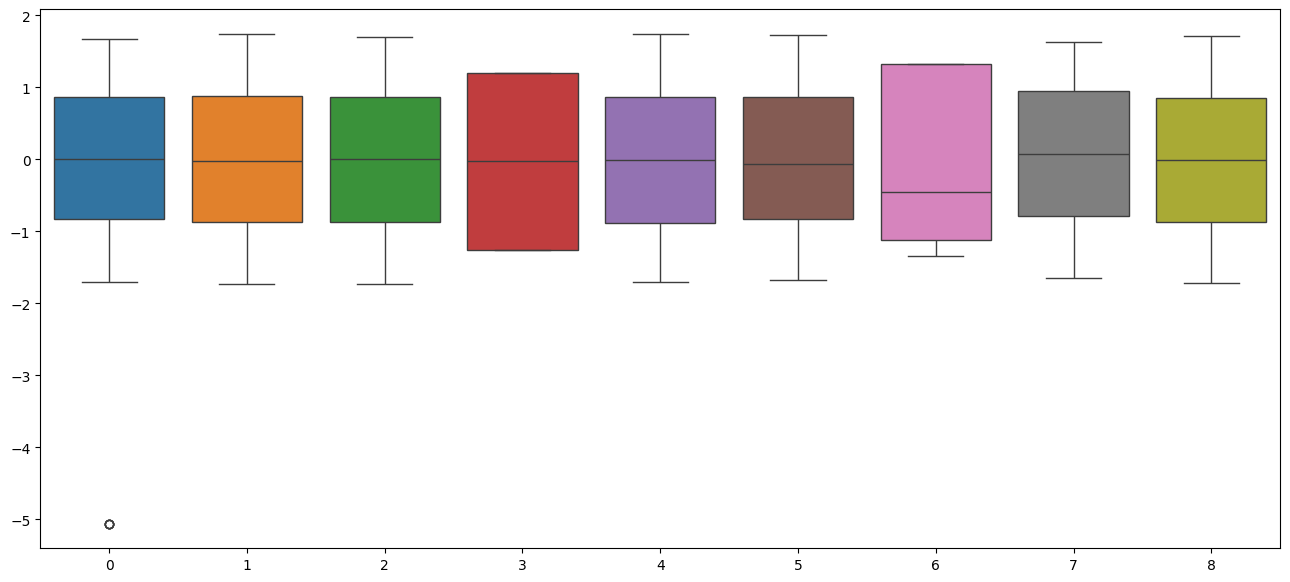

In [14]:
plt.figure(figsize=(16, 7))
sns.boxplot(data=X_train)

In [15]:

model = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
model.fit(X_train, y_train)

ypred = model.predict(X_test)

In [16]:
print("Classification Report:\n", classification_report(y_test, ypred))
print("Confusion Matrix:\n", confusion_matrix(y_test, ypred))
print("Accuracy Score:", accuracy_score(y_test, ypred))


Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00        23
           1       1.00      1.00      1.00        54
           2       1.00      1.00      1.00        79
           3       1.00      1.00      1.00      1142
           4       1.00      1.00      1.00       232

    accuracy                           1.00      1530
   macro avg       1.00      1.00      1.00      1530
weighted avg       1.00      1.00      1.00      1530

Confusion Matrix:
 [[  23    0    0    0    0]
 [   0   54    0    0    0]
 [   0    0   79    0    0]
 [   0    0    0 1142    0]
 [   0    0    0    0  232]]
Accuracy Score: 1.0


In [17]:
from sklearn.model_selection import GridSearchCV

params = {
    'n_estimators': [100, 200, 300],
    'max_depth': [None, 10, 20, 30],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'max_features': ['sqrt', 'log2'],
    'bootstrap': [True],
    'class_weight': [None, 'balanced']
}

grid =  GridSearchCV(
    estimator=model,
    param_grid=params,
    cv=5,
    scoring='f1_macro',
    n_jobs=-1,
    verbose=2
)

grid.fit(X_train, y_train)

print("Best Parameters:", grid.best_params_)
print("Best CV Score:", grid.best_score_)

best_model = grid.best_estimator_

Fitting 5 folds for each of 432 candidates, totalling 2160 fits
Best Parameters: {'bootstrap': True, 'class_weight': None, 'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 100}
Best CV Score: 0.9989159891598917


In [18]:
final_model = RandomForestClassifier(
    bootstrap=True,
    class_weight='balanced',
    max_depth=None,
    max_features='sqrt',
    min_samples_leaf=1,
    min_samples_split=2,
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

final_model.fit(X_train, y_train)
ypred_final = final_model.predict(X_test)

In [19]:
print("Classification Report:\n", classification_report(y_test, ypred_final))
print("Confusion Matrix:\n", confusion_matrix(y_test, ypred_final))
print("Accuracy Score:", accuracy_score(y_test, ypred_final))

Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00        23
           1       1.00      1.00      1.00        54
           2       1.00      1.00      1.00        79
           3       1.00      1.00      1.00      1142
           4       1.00      1.00      1.00       232

    accuracy                           1.00      1530
   macro avg       1.00      1.00      1.00      1530
weighted avg       1.00      1.00      1.00      1530

Confusion Matrix:
 [[  23    0    0    0    0]
 [   0   54    0    0    0]
 [   0    0   79    0    0]
 [   0    0    0 1142    0]
 [   0    0    0    0  232]]
Accuracy Score: 1.0
